In [57]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

CITY = "Hyderabad"

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "regions"
OUTPUT_DIR = PROJECT_DIR / f"series2_outputs/{CITY.lower()}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(DATA_DIR / f"{CITY}_cell_year_2015_2025.csv")
dw = pd.read_csv(DATA_DIR / f"{CITY}_builtup_2016_2025.csv")

data["year"] = pd.to_numeric(data["year"], errors="coerce")

VARIABLES = ["lst_c", "ndbi", "ndvi", "built_fraction"]
YEARS = list(range(2015, 2026))
MAP_YEARS = [2016, 2020, 2025]

sns.set_theme(style="whitegrid")

print(f"City: {CITY}")
print(f"Records: {len(data):,}")
print(f"Unique grid cells: {data['grid_id'].nunique():,}")
print(f"Years present: {sorted(data['year'].dropna().unique().astype(int))}")
print(f"Output directory: {OUTPUT_DIR}")
display(data.head())


City: Hyderabad
Records: 49,214
Unique grid cells: 4,474
Years present: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Output directory: d:\sparkle\urban heat lockin\series2_outputs\hyderabad


,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix
0,Hyderabad_25195_7284,Hyderabad,Hyderabad,2015,45.555397,0.271104,0.065036,5.000000,6,0,Landsat 8
1,Hyderabad_25195_7284,Hyderabad,Hyderabad,2016,47.375941,0.213630,0.078798,6.000000,8,0,Landsat 8
2,Hyderabad_25195_7284,Hyderabad,Hyderabad,2017,45.978338,0.226697,0.091812,6.000000,7,0,Landsat 8
3,Hyderabad_25195_7284,Hyderabad,Hyderabad,2018,45.197868,0.246702,0.079228,6.428984,8,0,Landsat 8
4,Hyderabad_25195_7284,Hyderabad,Hyderabad,2019,47.553355,0.216231,0.087316,4.000000,7,0,Landsat 8


In [58]:
data = data.merge(
        dw[
            [
                "grid_id",
                "year",
                "built_fraction",
                "built_probability_mean",
                "valid_observation_count",
                "seasonal_image_count",
            ]
        ],
        on=["grid_id", "year"],
        how="left",
        validate="one_to_one",
        indicator=True,
    )

data.head()

,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix,built_fraction,built_probability_mean,valid_observation_count,seasonal_image_count,_merge
0,Hyderabad_25195_7284,Hyderabad,Hyderabad,2015,45.555397,0.271104,0.065036,5.000000,6,0,Landsat 8,NaN,NaN,NaN,NaN,left_only
1,Hyderabad_25195_7284,Hyderabad,Hyderabad,2016,47.375941,0.213630,0.078798,6.000000,8,0,Landsat 8,0.894086,0.541258,12.000000,24.0,both
2,Hyderabad_25195_7284,Hyderabad,Hyderabad,2017,45.978338,0.226697,0.091812,6.000000,7,0,Landsat 8,0.909608,0.548792,8.279658,20.0,both
3,Hyderabad_25195_7284,Hyderabad,Hyderabad,2018,45.197868,0.246702,0.079228,6.428984,8,0,Landsat 8,0.907318,0.560371,26.000000,30.0,both
4,Hyderabad_25195_7284,Hyderabad,Hyderabad,2019,47.553355,0.216231,0.087316,4.000000,7,0,Landsat 8,0.934511,0.576655,28.241581,40.0,both


In [59]:
data = data[data['year']>=2016]
data.head()

,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix,built_fraction,built_probability_mean,valid_observation_count,seasonal_image_count,_merge
1,Hyderabad_25195_7284,Hyderabad,Hyderabad,2016,47.375941,0.213630,0.078798,6.000000,8,0,Landsat 8,0.894086,0.541258,12.000000,24.0,both
2,Hyderabad_25195_7284,Hyderabad,Hyderabad,2017,45.978338,0.226697,0.091812,6.000000,7,0,Landsat 8,0.909608,0.548792,8.279658,20.0,both
3,Hyderabad_25195_7284,Hyderabad,Hyderabad,2018,45.197868,0.246702,0.079228,6.428984,8,0,Landsat 8,0.907318,0.560371,26.000000,30.0,both
4,Hyderabad_25195_7284,Hyderabad,Hyderabad,2019,47.553355,0.216231,0.087316,4.000000,7,0,Landsat 8,0.934511,0.576655,28.241581,40.0,both
5,Hyderabad_25195_7284,Hyderabad,Hyderabad,2020,46.430147,0.228635,0.083640,4.000000,7,0,Landsat 8,0.983629,0.603927,18.023884,34.0,both


,records,unique_cells,mean_observations
year,,,
2015,NaN,NaN,NaN
2016,4474.0,4474.0,5.138060
2017,4474.0,4474.0,5.888354
2018,4474.0,4474.0,6.126923
2019,4474.0,4474.0,4.108927
2020,4474.0,4474.0,4.412845
2021,4474.0,4474.0,6.237590
2022,4474.0,4474.0,9.498523
2023,4474.0,4474.0,9.366044


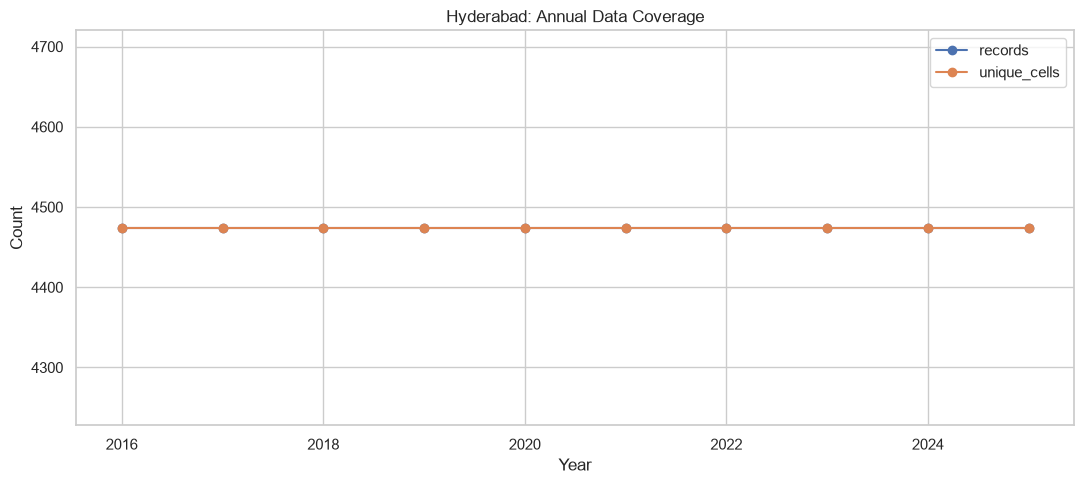

,missing_count,missing_percent
lst_c,0,0.0
ndbi,0,0.0
ndvi,0,0.0
built_fraction,0,0.0
n_obs_mean,0,0.0


In [60]:

# Number of records and unique grid cells per year
year_coverage = (
    data.groupby("year")
    .agg(
        records=("grid_id", "size"),
        unique_cells=("grid_id", "nunique"),
        mean_observations=("n_obs_mean", "mean")
    )
    .reindex(YEARS)
)

display(year_coverage)

ax = year_coverage[["records", "unique_cells"]].plot(
    figsize=(11, 5), marker="o"
)
ax.set_title(f"{CITY}: Annual Data Coverage")
ax.set_xlabel("Year")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_annual_coverage.png", dpi=200)
plt.show()

# Missing values
missing = data[VARIABLES + ["n_obs_mean"]].isna().sum().to_frame("missing_count")
missing["missing_percent"] = missing["missing_count"] / len(data) * 100
display(missing)

missing.to_csv(OUTPUT_DIR / "missing_values.csv")


['lst_c', 'ndbi', 'ndvi', 'built_fraction']


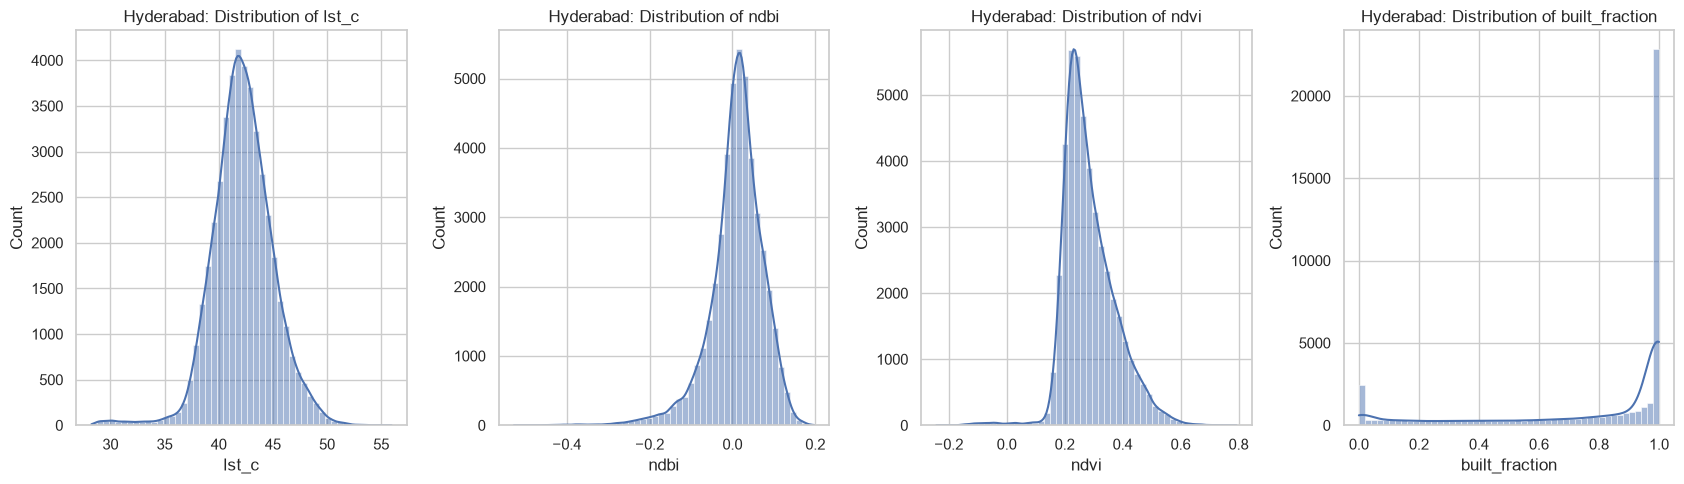

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
lst_c,44740.0,42.233257,2.809270,28.241128,34.352052,38.094892,40.557477,42.177205,43.924322,46.852619,49.039951,55.951347
ndbi,44740.0,0.009697,0.065024,-0.527885,-0.205914,-0.104140,-0.019822,0.015268,0.049286,0.103018,0.133611,0.196902
ndvi,44740.0,0.285878,0.089444,-0.242541,0.127598,0.180972,0.224944,0.267995,0.335519,0.454962,0.540933,0.792828
built_fraction,44740.0,0.775923,0.329077,0.000000,0.000000,0.010053,0.633314,0.985365,1.000000,1.000000,1.000000,1.000000


In [61]:
print(VARIABLES)

fig, axes = plt.subplots(1, 4, figsize=(17, 5))

for ax, variable in zip(axes, VARIABLES):
    sns.histplot(
        data=data,
        x=variable,
        bins=50,
        kde=True,
        ax=ax
    )
    ax.set_title(f"{CITY}: Distribution of {variable}")
    ax.set_xlabel(variable)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_variable_distributions.png", dpi=200)
plt.show()

display(data[VARIABLES].describe(percentiles=[
    0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99
]).T)


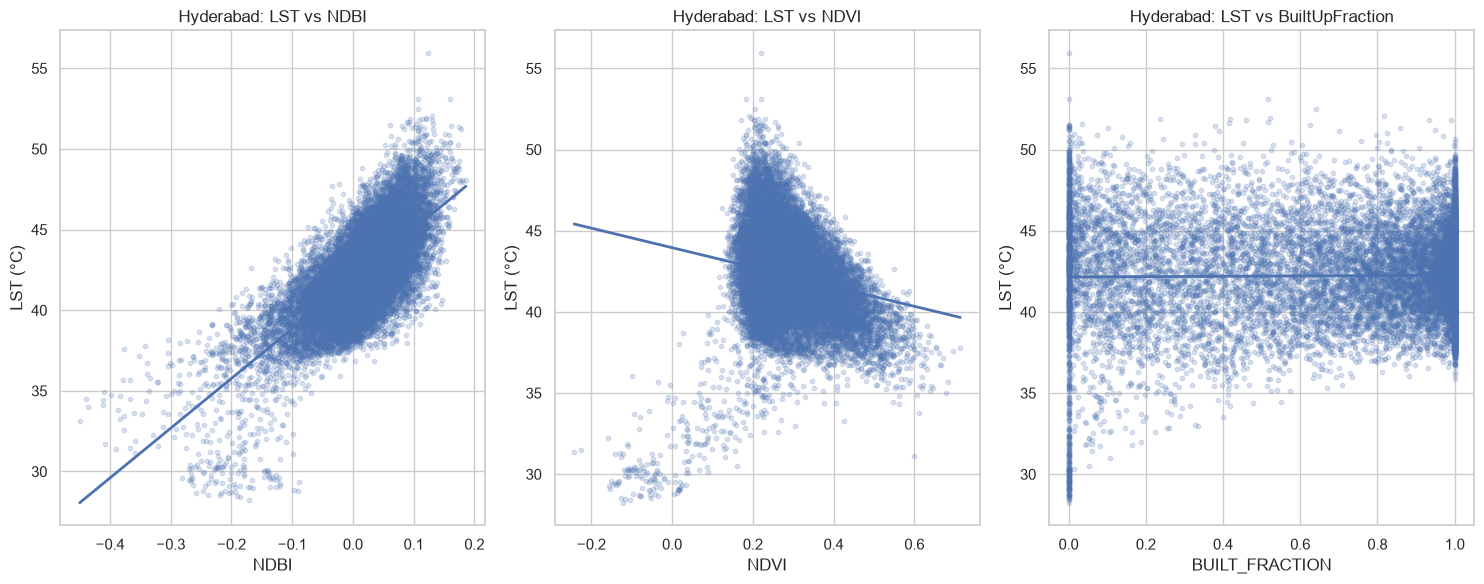

In [62]:

plot_data = data.dropna(subset=["lst_c", "ndbi", "ndvi"]).copy()

plot_sample = plot_data.sample(
    n=min(20000, len(plot_data)),
    random_state=42
)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI"),
    (axes[2], "built_fraction", "LST vs BuiltUpFraction")
]:
    sns.regplot(
        data=plot_sample,
        x=xvar,
        y="lst_c",
        ax=ax,
        scatter_kws={"alpha": 0.2, "s": 10},
        line_kws={"linewidth": 2},
        ci=None
    )
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel(xvar.upper())
    ax.set_ylabel("LST (°C)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_lst_relationships.png", dpi=200)
plt.show()


In [63]:

PAIRS = [
    ("lst_c", "ndbi"),
    ("lst_c", "ndvi"),
    ("ndbi", "ndvi"),
    ("lst_c", "built_fraction")
]

def calculate_correlations(df):
    results = []

    for x, y in PAIRS:
        pair = df[[x, y]].replace([np.inf, -np.inf], np.nan).dropna()
        n = len(pair)

        result = {
            "variable_1": x,
            "variable_2": y,
            "n": n,
            "pearson_r": np.nan,
            "pearson_p": np.nan,
            "spearman_rho": np.nan,
            "spearman_p": np.nan
        }

        if n >= 3 and pair[x].nunique() > 1 and pair[y].nunique() > 1:
            r, p = pearsonr(pair[x], pair[y])
            rho, sp = spearmanr(pair[x], pair[y])

            result.update({
                "pearson_r": r,
                "pearson_p": p,
                "spearman_rho": rho,
                "spearman_p": sp
            })

        results.append(result)

    return pd.DataFrame(results)

pooled_corr = calculate_correlations(data)
display(pooled_corr)
pooled_corr.to_csv(OUTPUT_DIR / "pooled_correlations.csv", index=False)

annual_corr = pd.concat(
    [
        calculate_correlations(group).assign(year=int(year))
        for year, group in data.groupby("year")
    ],
    ignore_index=True
)

display(annual_corr)
annual_corr.to_csv(OUTPUT_DIR / "annual_correlations.csv", index=False)


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,lst_c,ndbi,44740,0.719012,0.000000,0.673127,0.000000e+00
1,lst_c,ndvi,44740,-0.206487,0.000000,-0.285268,0.000000e+00
2,ndbi,ndvi,44740,-0.389766,0.000000,-0.440423,0.000000e+00
3,lst_c,built_fraction,44740,0.011313,0.016715,-0.055796,3.431072e-32


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p,year
0,lst_c,ndbi,4474,0.768969,0.000000e+00,0.736292,0.000000e+00,2016
1,lst_c,ndvi,4474,-0.160912,2.461751e-27,-0.167321,1.884358e-29,2016
2,ndbi,ndvi,4474,-0.287792,4.573134e-86,-0.293271,1.887004e-89,2016
3,lst_c,built_fraction,4474,-0.145923,1.016500e-22,-0.284989,2.306187e-84,2016
4,lst_c,ndbi,4474,0.799944,0.000000e+00,0.778008,0.000000e+00,2017
5,lst_c,ndvi,4474,-0.127183,1.349880e-17,-0.158037,2.054638e-26,2017
6,ndbi,ndvi,4474,-0.392275,1.664260e-164,-0.390562,5.762066e-163,2017
7,lst_c,built_fraction,4474,-0.132726,4.890260e-19,-0.246113,1.017197e-62,2017
8,lst_c,ndbi,4474,0.778920,0.000000e+00,0.769360,0.000000e+00,2018
9,lst_c,ndvi,4474,-0.173288,1.689689e-31,-0.240917,4.254212e-60,2018


lst_c                                   ndbi                      \
           mean     median       std   count      mean    median       std   
year                                                                         
2015        NaN        NaN       NaN     NaN       NaN       NaN       NaN   
2016  45.163075  45.096699  2.330101  4474.0  0.031469  0.033150  0.062542   
2017  43.243242  43.088955  2.558511  4474.0  0.021425  0.025128  0.063583   
2018  40.838307  40.793335  2.424928  4474.0  0.004756  0.012159  0.063732   
2019  44.165798  43.993308  2.784740  4474.0  0.030109  0.030087  0.064234   
2020  42.444411  42.415689  2.202432  4474.0  0.018147  0.023053  0.064345   
2021  42.386068  42.452428  2.188400  4474.0  0.010258  0.016928  0.061625   
2022  41.749430  41.827698  2.244511  4474.0  0.007434  0.013728  0.059597   
2023  42.007348  42.229737  2.228802  4474.0 -0.029882 -0.018692  0.062271   
2024  41.066318  41.006612  2.081224  4474.0  0.011298  0.016832  0.061193   
2025  39.268573  39.252257  1.885298  4474.0 -0.008046  0.000185  0.063414   

                  ndvi                             built_fraction            \
       count      mean    median       std   count           mean    median   
year                                                                          
2015     NaN       NaN       NaN       NaN     NaN            NaN       NaN   
2016  4474.0  0.244238  0.233629  0.066192  4474.0       0.729976  0.951287   
2017  4474.0  0.273791  0.258644  0.081968  4474.0       0.751113  0.967578   
2018  4474.0  0.294212  0.278681  0.085170  4474.0       0.760179  0.972816   
2019  4474.0  0.255147  0.242467  0.073956  4474.0       0.766675  0.985824   
2020  4474.0  0.292937  0.278360  0.082278  4474.0       0.783162  0.989439   
2021  4474.0  0.296104  0.281085  0.085392  4474.0       0.771520  0.982888   
2022  4474.0  0.283656  0.271870  0.081076  4474.0       0.788285  0.989956   
2023  4474.0  0.333099  0.306816  0.115730  4474.0       0.800199  0.990136   
2024  4474.0  0.275817  0.263071  0.080196  4474.0       0.808144  0.999618   
2025  4474.0  0.309781  0.289281  0.098883  4474.0       0.799979  0.994954   

                        
           std   count  
year                    
2015       NaN     NaN  
2016  0.355288  4474.0  
2017  0.344432  4474.0  
2018  0.338358  4474.0  
2019  0.338209  4474.0  
2020  0.324266  4474.0  
2021  0.331702  4474.0  
2022  0.318590  4474.0  
2023  0.307605  4474.0  
2024  0.307819  4474.0  
2025  0.312827  4474.0

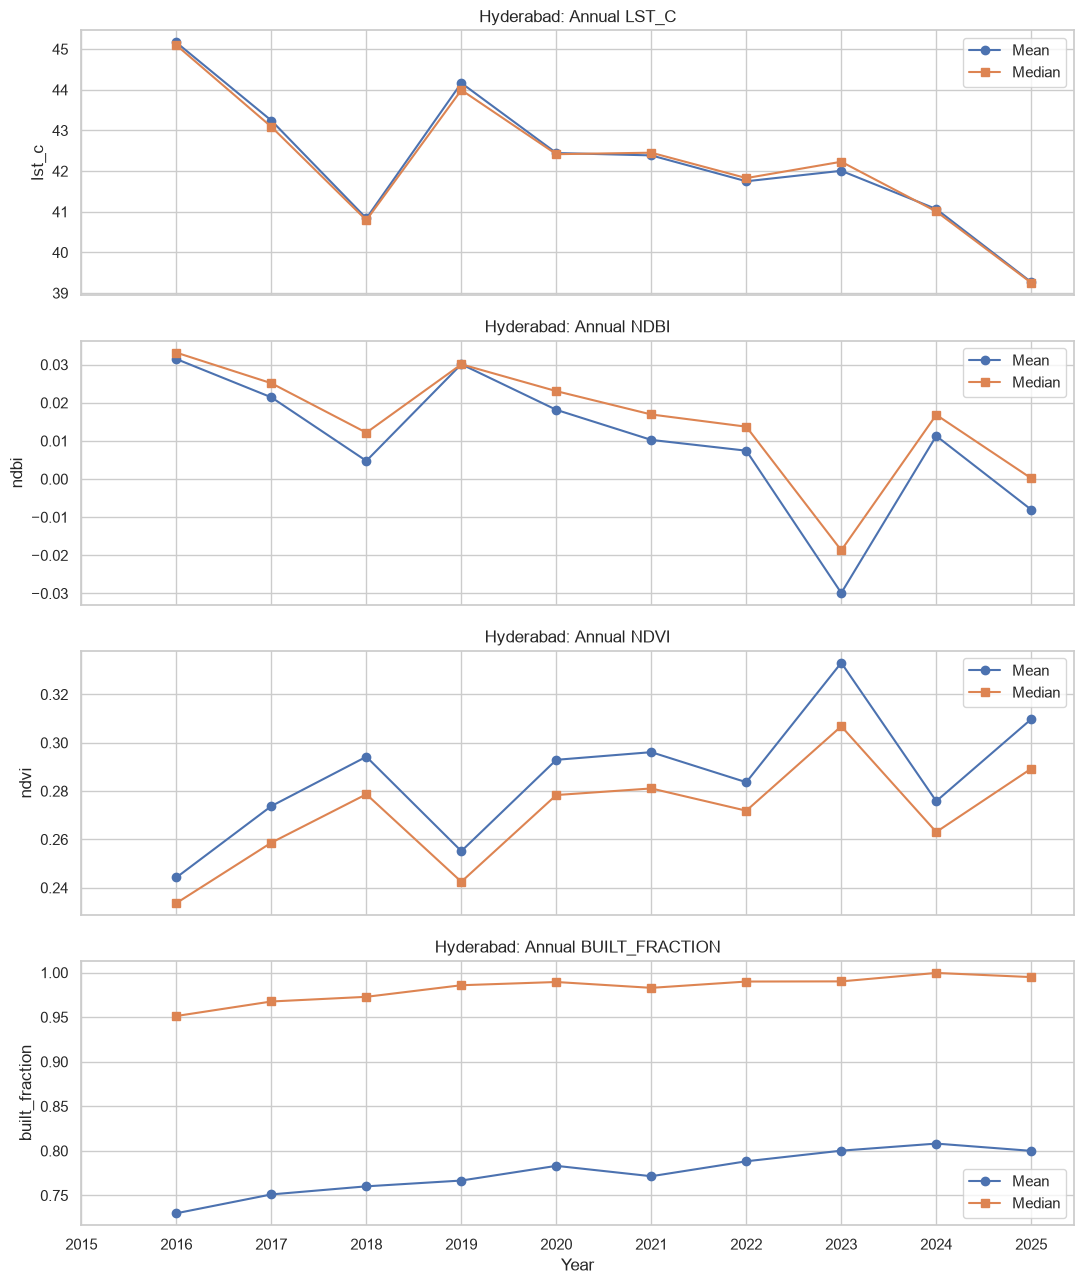

In [64]:

annual_stats = (
    data.groupby("year")[VARIABLES]
    .agg(["mean", "median", "std", "count"])
    .reindex(YEARS)
)

display(annual_stats)
annual_stats.to_csv(OUTPUT_DIR / "annual_summary_statistics.csv")

fig, axes = plt.subplots(4, 1, figsize=(11, 13), sharex=True)

for ax, variable in zip(axes, VARIABLES):
    stats = data.groupby("year")[variable].agg(["mean", "median"])

    ax.plot(stats.index, stats["mean"], marker="o", label="Mean")
    ax.plot(stats.index, stats["median"], marker="s", label="Median")

    ax.set_title(f"{CITY}: Annual {variable.upper()}")
    ax.set_ylabel(variable)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(YEARS)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_annual_trends.png", dpi=200)
plt.show()


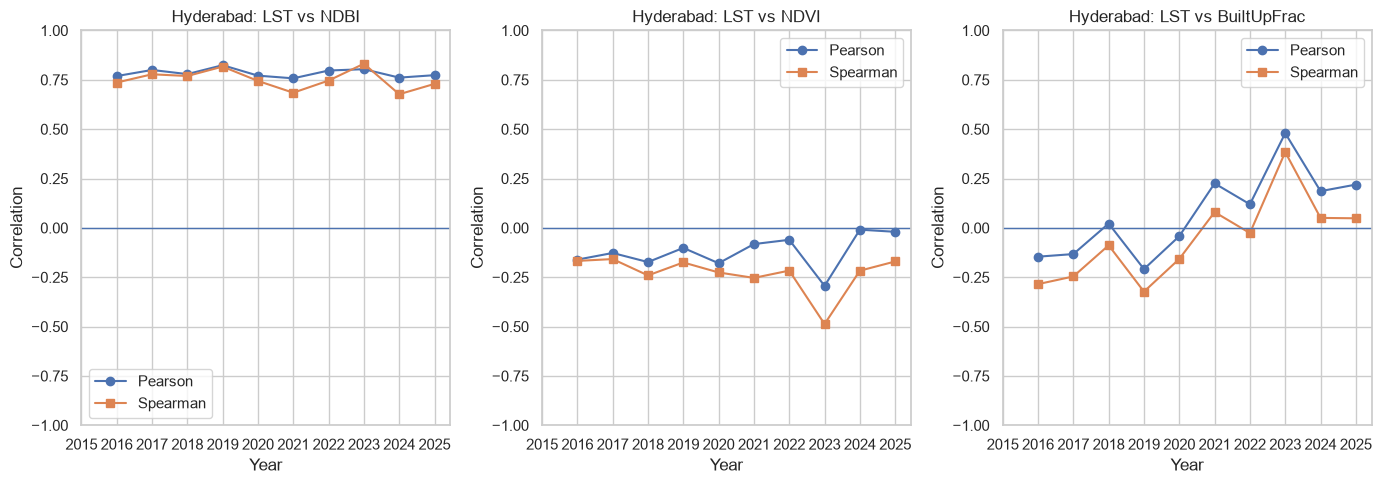

In [65]:

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI"),
    (axes[2], "built_fraction", "LST vs BuiltUpFrac")
]:
    subset = annual_corr[
        (annual_corr["variable_1"] == "lst_c") &
        (annual_corr["variable_2"] == xvar)
    ]

    ax.plot(
        subset["year"], subset["pearson_r"],
        marker="o", label="Pearson"
    )
    ax.plot(
        subset["year"], subset["spearman_rho"],
        marker="s", label="Spearman"
    )
    ax.axhline(0, linewidth=1)
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Correlation")
    ax.set_ylim(-1, 1)
    ax.set_xticks(YEARS)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_annual_correlations.png", dpi=200)
plt.show()


Grid columns: ['grid_id', 'in_frac', 'city_id', 'geometry']
Grid CRS: PROJCS["WGS 84 / World Cylindrical Equal Area",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433]],PROJECTION["Cylindrical_Equal_Area"],PARAMETER["central_meridian",0],PARAMETER["standard_parallel_1",30],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["m",1],AXIS["X",EAST],AXIS["Y",NORTH]]
Number of grid cells: 4474


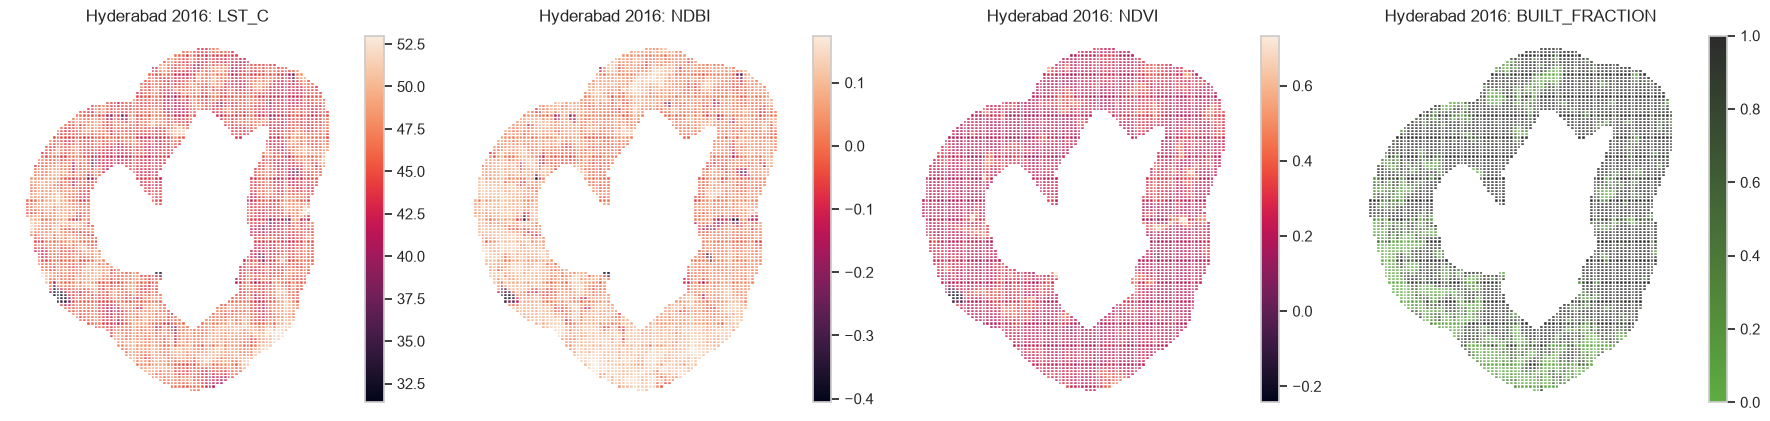

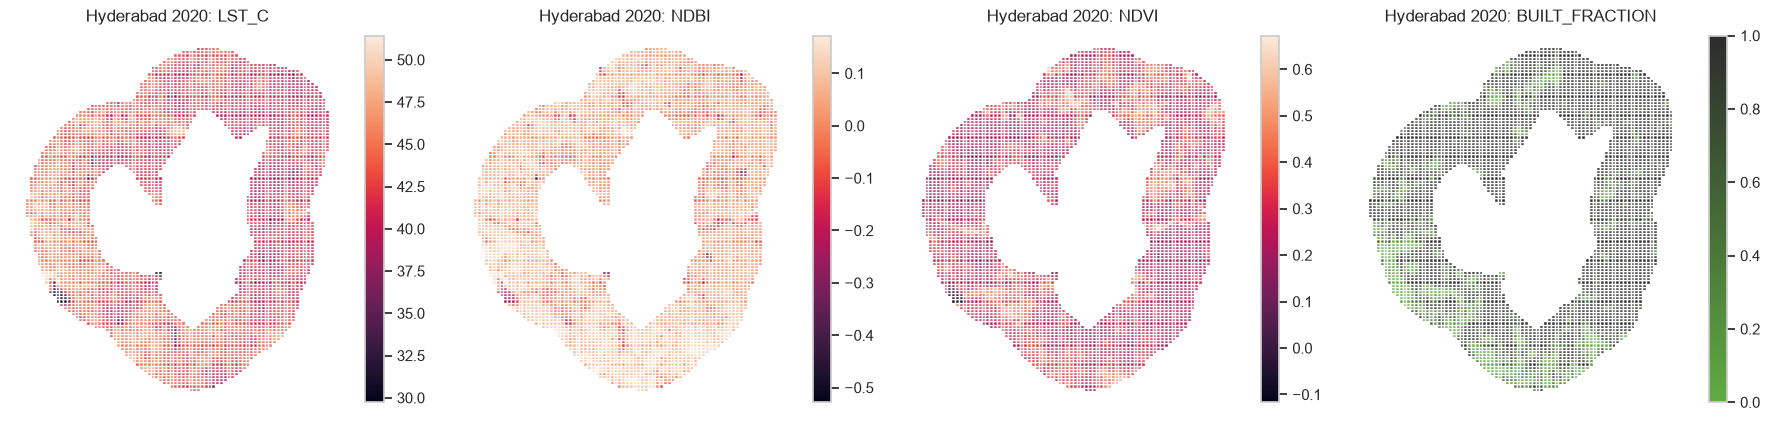

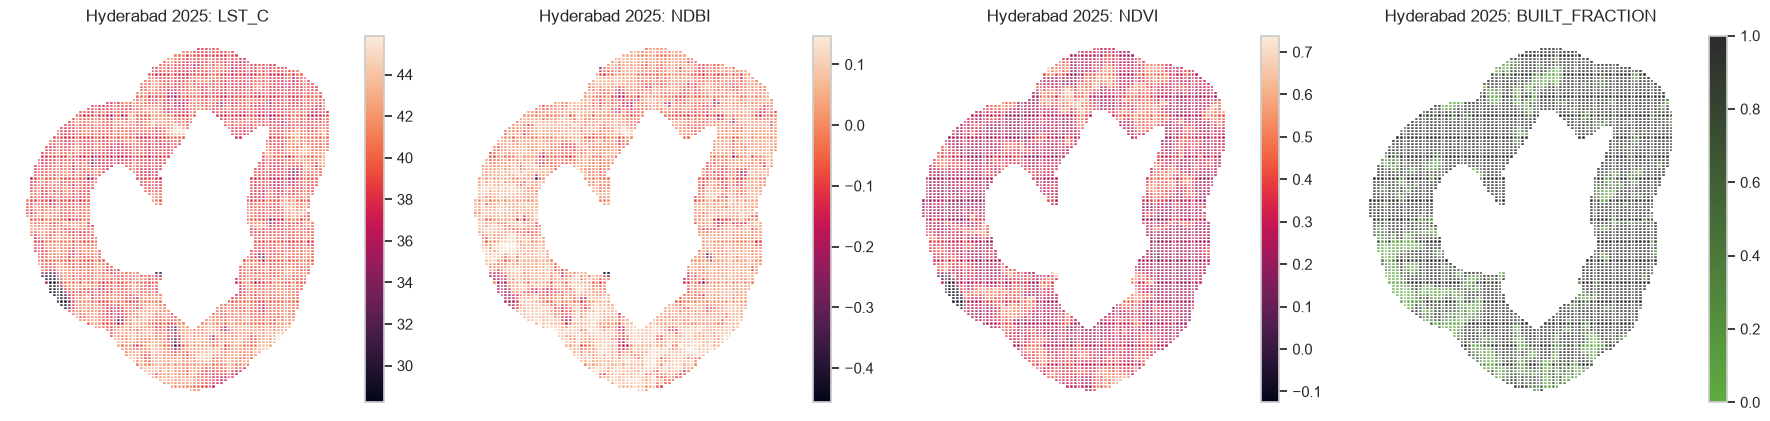

In [79]:

import geopandas as gpd
from pathlib import Path

# Change this path to your actual 300 m grid shapefile
SHAPEFILE_PATH = PROJECT_DIR / "grids" / f"{CITY}_Grid_300m.shp"

if not SHAPEFILE_PATH.exists():
    print(f"Shapefile not found: {SHAPEFILE_PATH}")
else:
    grid = gpd.read_file(SHAPEFILE_PATH)

    print("Grid columns:", grid.columns.tolist())
    print("Grid CRS:", grid.crs)
    print("Number of grid cells:", len(grid))

    if "grid_id" not in grid.columns:
        raise ValueError(
            "The shapefile has no grid_id column. "
            "Check its column names and identify the matching grid ID field."
        )

    grid["grid_id"] = grid["grid_id"].astype(str)
    data["grid_id"] = data["grid_id"].astype(str)

    if grid.crs is None:
        raise ValueError("The shapefile has no CRS defined.")

    grid = grid.to_crs("EPSG:4326")

    for year in MAP_YEARS:
        year_data = data.loc[
            data["year"] == year,
            ["grid_id"] + VARIABLES
        ]

        joined = grid.merge(
            year_data,
            on="grid_id",
            how="left",
            validate="one_to_one"
        )

        fig, axes = plt.subplots(1, 4, figsize=(18, 6))

        for ax, variable in zip(axes, VARIABLES):
            plot_kwargs = {
                "column": variable,
                "ax": ax,
                "legend": True,
                "missing_kwds": {
                    "color": "lightgrey",
                    "label": "No data"
                },
                "legend_kwds": {"shrink": 0.65}
            }

            if variable=="built_fraction":
                from matplotlib.colors import LinearSegmentedColormap
                built_cmap = LinearSegmentedColormap.from_list(
                    "built_intensity",
                    ["#5fac41", "#2c2b2c"][::1]
                )
                plot_kwargs["cmap"] = built_cmap
                plot_kwargs["vmin"] = 0
                plot_kwargs["vmax"] = 1
            
            joined.plot(**plot_kwargs)
            ax.set_title(f"{CITY} {year}: {variable.upper()}")
            ax.set_axis_off()

        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"map_{CITY}_{year}.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
